In [25]:
import pandas as pd # manejo de tablas
from pathlib import Path # rutas de archivos y carpetas de forma
import cv2 # procesamiento de imágenes
import matplotlib.pyplot as plt # mostrar imágenes y gráficos 
import numpy as np # operaciones con matrices.

## Carga y visualización inicial de las imágenes

Las imágenes se encuentran organizadas en subcarpetas dentro de `Data`,
según su diagnóstico: carcinoma basocelular (BCC), carcinoma escamoso
(SCC) y queratosis seborreica (SK).

Se carga y visualiza una imagen de cada grupo para inspeccionar sus
características y detectar elementos que puedan afectar el procesamiento.
Las imágenes se convierten de BGR a RGB para representar correctamente
sus colores.

En esta etapa se conserva la resolución original y no se aplican filtros.

BCC: 22 imágenes
SCC: 16 imágenes
SK: 21 imágenes


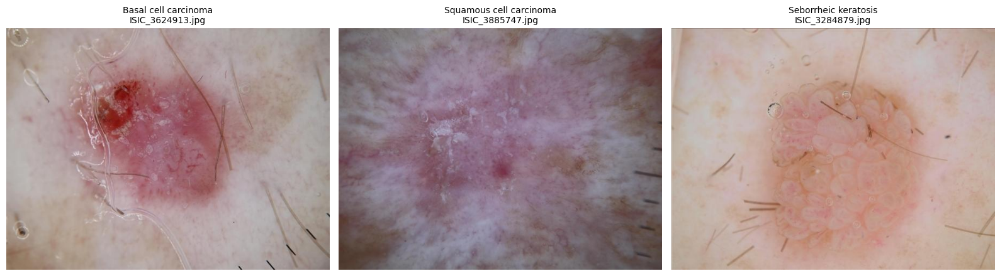

In [26]:
# Carpeta raíz donde están las imágenes. 
carpeta_data = Path("Data")

# Diccionario que asocia el nombre de cada subcarpeta (clave) con el nombre completo del diagnóstico (valor), usado en los títulos
grupos = {
    "BCC": "Basal cell carcinoma",
    "SCC": "Squamous cell carcinoma",
    "SK": "Seborrheic keratosis",
}

# Diccionario vacío donde se guardará una imagen por grupo.
# Estas tres imágenes son las que usamos en el resto del notebook
imagenes = {}

# Crear una figura
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# zip recorre en paralelo cada eje (ax) y cada par (carpeta, diagnóstico)
for ax, (carpeta, diagnostico) in zip(axes, grupos.items()):

    # Listar todos los archivos dentro de la subcarpeta (ej. Data/BCC), ordenado por nombre
    archivos = sorted(
        p for p in (carpeta_data / carpeta).rglob("*")
    )

    # Si la carpeta está vacía, se detiene la ejecución con un error
    if not archivos:
        raise FileNotFoundError(f"No hay imágenes en {carpeta}")

    # Se elige la imagen en la posición 6 si es que hay y sino la primera
    ruta = archivos[6] if len(archivos) > 1 else archivos[0]

    # Leer la imagen. OpenCV necesita la ruta como texto (str).
    # Devuelve una matriz de alto x ancho x 3 con valores de 0 a 255
    imagen = cv2.imread(str(ruta))

    # cv2.imread no da error si falla: devuelve None. Por eso se verifica
    if imagen is None:
        raise ValueError(f"No se pudo leer: {ruta}")

    # OpenCV carga los canales en orden BGR (azul, verde, rojo), pero matplotlib los interpreta como RGB. Sin esta conversión,
    # los colores se verían invertidos
    imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    # Guardar la imagen para el preprocesamiento
    imagenes[carpeta] = imagen_rgb

    # Mostrar la imagen
    ax.imshow(imagen_rgb)
    ax.set_title(f"{diagnostico}\n{ruta.name}", fontsize=10)
    ax.axis("off")

    # Informar cuántas imágenes hay en cada grupo
    print(f"{carpeta}: {len(archivos)} imágenes")

# Ajustar los márgenes 
plt.tight_layout()
plt.show()

### Observaciones iniciales

En los ejemplos seleccionados se observan diferencias de color, contraste
y apariencia superficial. La imagen BCC presenta una región rosada de
bajo contraste respecto de la piel circundante. En la imagen SCC se
observan numerosos pelos y estructuras circulares compatibles con
burbujas. La imagen SK presenta una región de pigmentación heterogénea.

Estos elementos pueden interferir en la segmentación y modificar las
mediciones de color y textura. Por ello, se evaluarán técnicas de
preprocesamiento procurando preservar los detalles de la lesión.

Estas observaciones corresponden únicamente a las imágenes mostradas
y no se consideran características generales de cada diagnóstico.

## Caracterización técnica del conjunto de imágenes

Se recorren todas las imágenes de las tres carpetas y se registran sus
propiedades: formato, dimensiones, cantidad de canales, tipo de dato y
profundidad de bits, además de los valores mínimo y máximo de intensidad.

El objetivo es verificar si el conjunto es homogéneo antes de procesarlo,
ya que diferencias de resolución o profundidad de bits obligarían a
normalizar las imágenes.

In [27]:
# Extensiones de archivo que se consideran imágenes
extensiones = {".jpg", ".jpeg", ".png"}

# Lista donde se acumula un diccionario por imagen
filas = []

# Recorrer cada grupo (BCC, SCC, SK)
for carpeta in grupos:
    # iterdir() lista los archivos de la carpeta (sin entrar en
    # subcarpetas); sorted los ordena alfabéticamente
    for ruta in sorted((carpeta_data / carpeta).iterdir()):

        # Saltear los archivos cuya extensión no es de imagen.
        if ruta.suffix.lower() not in extensiones:
            continue

        # IMREAD_UNCHANGED lee la imagen tal cual está guardada, sin convertirla
        imagen = cv2.imread(str(ruta), cv2.IMREAD_UNCHANGED)

        # shape devuelve (alto, ancho, canales) en imágenes color
        # o (alto, ancho) en imágenes en escala de grises.
        alto, ancho = imagen.shape[:2]

        # ndim = cantidad de dimensiones de la matriz.
        canales = 1 if imagen.ndim == 2 else imagen.shape[2]

        # Guardar las propiedades de esta imagen
        filas.append({
            "Grupo": carpeta,
            "Archivo": ruta.name,
            "Formato": ruta.suffix.lower(),
            "Ancho (px)": ancho,
            "Alto (px)": alto,
            "Canales": canales,
            "Tipo de dato": str(imagen.dtype),
            "Bits por canal": imagen.dtype.itemsize * 8,
            "Mínimo": int(imagen.min()),
            "Máximo": int(imagen.max()),
        })

# Convertir la lista de diccionarios en una tabla
caracteristicas = pd.DataFrame(filas)

print(f"Total de imágenes: {len(caracteristicas)}\n")

# Resumir la tabla por grupo
resumen = caracteristicas.groupby("Grupo").agg(
    Cantidad=("Archivo", "count"),
    Ancho=("Ancho (px)", lambda x: sorted(set(x))),
    Alto=("Alto (px)", lambda x: sorted(set(x))),
    Canales=("Canales", lambda x: sorted(set(x))),
    Bits=("Bits por canal", lambda x: sorted(set(x))),
    Formato=("Formato", lambda x: sorted(set(x))),
)
print(resumen)

Total de imágenes: 59

       Cantidad  Ancho   Alto Canales Bits Formato
Grupo                                             
BCC          22  [600]  [450]     [3]  [8]  [.jpg]
SCC          16  [600]  [450]     [3]  [8]  [.jpg]
SK           21  [600]  [450]     [3]  [8]  [.jpg]


### Resultado de la caracterización técnica

Las 59 imágenes (22 BCC, 16 SCC y 21 SK) están en formato JPEG, tienen
una resolución de 600 × 450 píxeles y tres canales de color con 8 bits
por canal (valores entre 0 y 255).

Al ser un conjunto homogéneo, no se requiere redimensionar ni normalizar
la profundidad de bits. Se debe considerar que JPEG utiliza compresión
con pérdida, que puede introducir artefactos de bloque y afectar las
mediciones de textura.

## Separación en espacios de color

Se descompone cada imagen seleccionada en sus canales RGB y HSV, y se
obtiene además su versión en escala de grises.

En RGB, cada canal representa la intensidad de rojo, verde y azul.
En HSV, el canal H representa el tono, S la saturación (pureza del color)
y V el valor o brillo. En OpenCV, H toma valores entre 0 y 179, mientras
que S y V van de 0 a 255.

El objetivo es identificar en qué canales la lesión presenta mayor
contraste respecto de la piel circundante, como criterio para elegir
la representación utilizada en la segmentación.

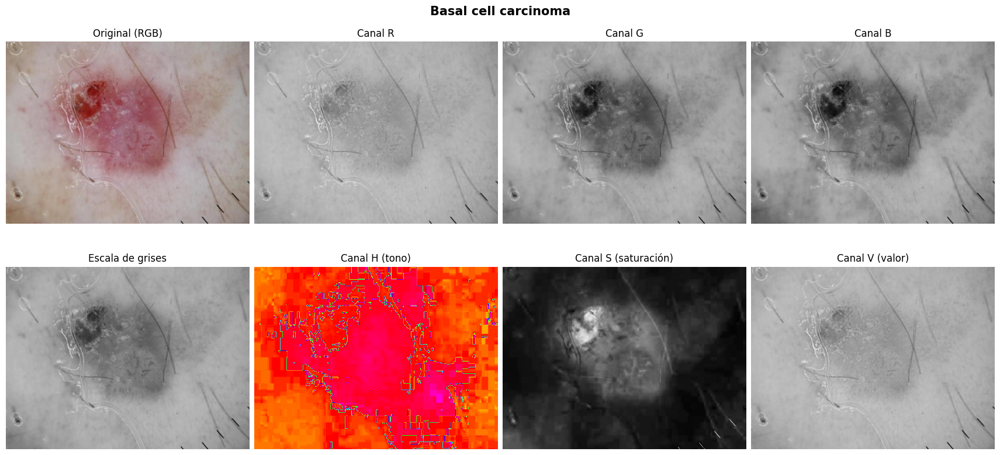

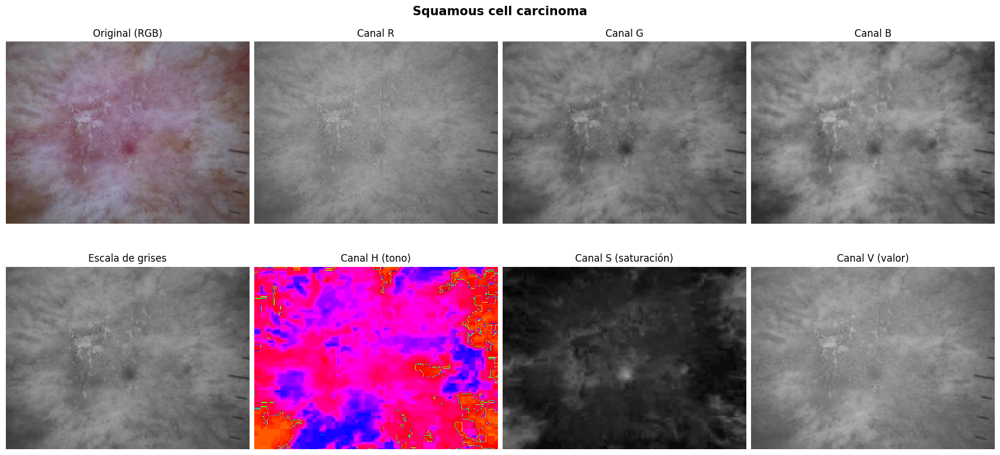

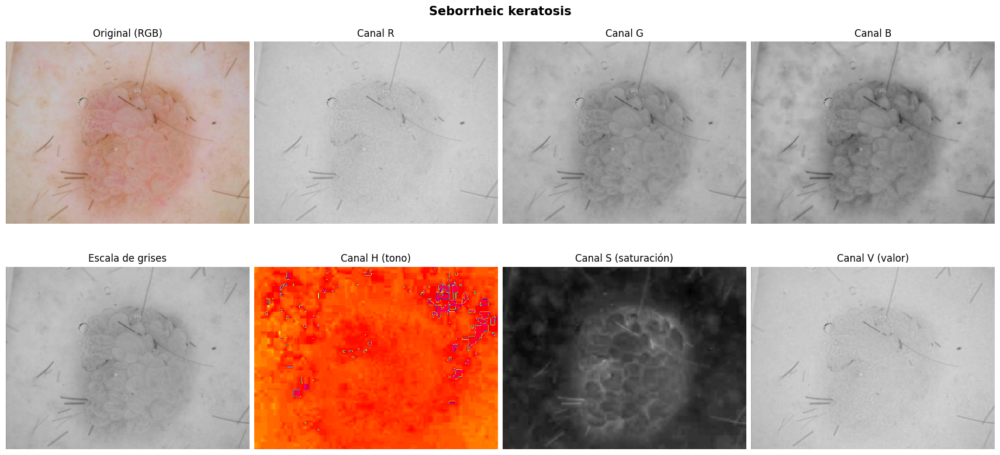

In [28]:
# Se genera una figura por cada una de las tres imágenes seleccionadas.
# "imagenes" ya contiene las imágenes en RGB 
for tipo, original in imagenes.items():

    # Convertir de RGB a HSV.
    hsv = cv2.cvtColor(original, cv2.COLOR_RGB2HSV)

    # Convertir a escala de grises 
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Lista de lo que se va a mostrar
    paneles = [
        ("Original (RGB)", original, None),
        ("Canal R", original[:, :, 0], "gray"),
        ("Canal G", original[:, :, 1], "gray"),
        ("Canal B", original[:, :, 2], "gray"),
        ("Escala de grises", gris, "gray"),
        ("Canal H (tono)", hsv[:, :, 0], "hsv"),
        ("Canal S (saturación)", hsv[:, :, 1], "gray"),
        ("Canal V (valor)", hsv[:, :, 2], "gray"),
    ]

    # Figura de 2 filas x 4 columnas = 8 paneles.    
    fig, axes = plt.subplots(
        2, 4, figsize=(17, 8), constrained_layout=True
    )

    # Título general de la figura
    fig.suptitle(grupos[tipo], fontsize=15, fontweight="bold")

    for ax, (nombre, imagen, cmap) in zip(axes.ravel(), paneles):

        if cmap is None:
            # Imagen color: se muestra directamente
            ax.imshow(imagen)

        elif cmap == "hsv":
            # El canal H se muestra con un mapa de colores circular, para ver el tono real que representa cada valor.
            # En OpenCV el tono va de 0 a 179 (no de 0 a 360)
            ax.imshow(imagen, cmap="hsv", vmin=0, vmax=179)

        else:
            # vmin y vmax fijan la escala en 0-255
            ax.imshow(imagen, cmap=cmap, vmin=0, vmax=255)

        ax.set_title(nombre)
        ax.axis("off")

    plt.show()

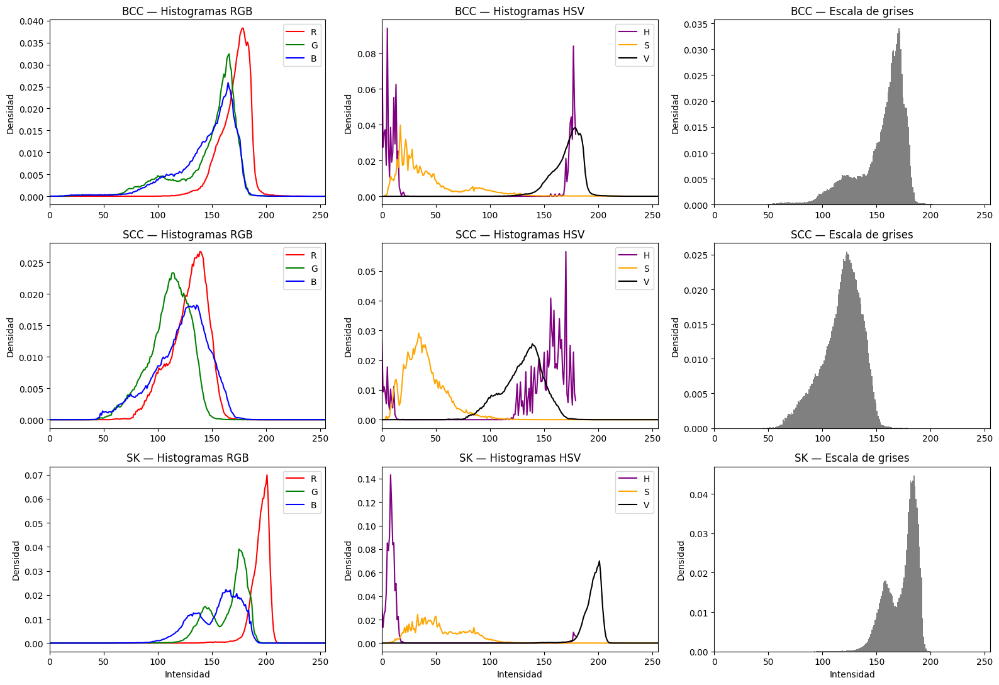

In [29]:
# Figura de 3 filas x 3 columnas
fig, axes = plt.subplots(3, 3, figsize=(16, 11))

# enumerate devuelve también el número de fila (0, 1, 2)
for fila, (tipo, original) in enumerate(imagenes.items()):
    hsv = cv2.cvtColor(original, cv2.COLOR_RGB2HSV)
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Columna 1: histogramas RGB
    ax = axes[fila, 0]

    # Se recorre cada canal: 0 (R), 1 (G), 2 (B),y se dibuja cada uno con su color
    for i, (canal, color) in enumerate(zip("RGB", ["red", "green", "blue"])):

        # calcHist cuenta cuántos píxeles tienen cada valor de intensidad.
        hist = cv2.calcHist([original], [i], None, [256], [0, 256])

        # Se divide por el total de píxeles para obtener proporciones en lugar de cantidades. 
        # ravel() pasa el resultado de columna (256x1) a vector para poder graficarlo
        ax.plot(hist.ravel() / hist.sum(), color=color, label=canal)

    ax.set_xlim(0, 255)
    ax.set_title(f"{tipo} — Histogramas RGB")
    ax.legend()

    # Columna 2: histogramas HSV
    ax = axes[fila, 1]

    # Igual que antes
    for i, (canal, color, maximo) in enumerate(
        zip(["H", "S", "V"], ["purple", "orange", "black"], [180, 256, 256])
    ):
        hist = cv2.calcHist([hsv], [i], None, [maximo], [0, maximo])
        ax.plot(hist.ravel() / hist.sum(), color=color, label=canal)

    ax.set_xlim(0, 255)
    ax.set_title(f"{tipo} — Histogramas HSV")
    ax.legend()

    # Columna 3: histograma en escala de grises
    ax = axes[fila, 2]
    ax.hist(gris.ravel(), bins=256, range=(0, 256),
            density=True, color="gray")
    ax.set_xlim(0, 255)
    ax.set_title(f"{tipo} — Escala de grises")

    for ax in axes[fila]:
        ax.set_ylabel("Densidad")

for ax in axes[2]:
    ax.set_xlabel("Intensidad")

plt.tight_layout()
plt.show()

In [30]:
# Lista donde se acumula una fila por cada combinación imagen-canal
filas = []

for tipo, original in imagenes.items():
    hsv = cv2.cvtColor(original, cv2.COLOR_RGB2HSV)
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Diccionario con los canales a analizar: nombre -> matriz 2D.
    canales = {
        "R": original[:, :, 0], "G": original[:, :, 1],
        "B": original[:, :, 2], "S": hsv[:, :, 1],
        "V": hsv[:, :, 2], "Gris": gris,
    }

    for nombre, canal in canales.items():
        filas.append({
            "Grupo": tipo,
            "Canal": nombre,
            "Media": canal.mean(),
            "Desvío": canal.std(),
            "Mínimo": int(canal.min()),
            "Máximo": int(canal.max()),
        })

estadisticas_canales = pd.DataFrame(filas)

# pivot reorganiza la tabla: una fila por canal y una columna por grupo
print(
    estadisticas_canales
    .pivot(index="Canal", columns="Grupo", values=["Media", "Desvío"])
    .round(1)
    .reindex(["R", "G", "B", "S", "V", "Gris"])
)

       Media               Desvío            
Grupo    BCC    SCC     SK    BCC   SCC    SK
Canal                                        
R      171.3  128.4  195.0   13.7  17.4   8.1
G      146.5  110.6  165.3   28.9  18.8  17.3
B      145.2  121.8  154.7   27.4  25.2  21.4
S       43.6   39.7   53.2   33.4  18.8  23.9
V      171.3  130.0  195.0   13.7  18.8   8.1
Gris   153.8  117.2  173.0   23.5  18.5  14.2


### Observaciones sobre los canales de color

En las tres imágenes, el canal R presenta valores altos y poco
contraste entre la lesión y la piel (desvío entre 8 y 17), ya que ambas
tienen un componente rojo importante. En BCC y SK, los canales G y B
muestran mayor variabilidad y la lesión se distingue con más claridad,
por lo que resultan más útiles para separarla del fondo. En SCC, la
lesión presenta bajo contraste en todos los canales.

El canal V coincide prácticamente con R, porque V toma el máximo de los
tres canales y en la piel ese máximo suele ser el rojo. En la imagen BCC,
el canal S resalta la región más pigmentada de la lesión.

En BCC y SK, el canal H se concentra cerca de 0 y de 179, ambos extremos
correspondientes a tonos rojizos; en SCC aparecen además tonos violáceos
y azulados. Por ser un ángulo, no se calcula su media, que no sería
representativa. Además, en las zonas de baja saturación (pelos, burbujas
y reflejos blanquecinos) el tono queda indefinido y aparecen valores
dispersos, por lo que H resulta poco confiable en esas regiones.

En escala de grises, el histograma de SK es bimodal, lo que sugiere dos
poblaciones (lesión y piel) separables por un umbral. En SCC el
histograma es unimodal, lo que complicará su segmentación por
umbralización.

Estas observaciones corresponden a una imagen por grupo y no se
generalizan a cada diagnóstico.

## Preprocesamiento: comparación de filtros de suavizado

Se comparan un filtro de mediana y un filtro gaussiano, utilizando
ventanas de 3 × 3 píxeles.

El filtro de mediana reemplaza cada valor por la mediana de su entorno.
El filtro gaussiano realiza un promedio ponderado, asignando mayor peso
a los píxeles cercanos al centro de la ventana.

Se aplica cada filtro de manera independiente sobre la imagen original.
Se evalúa visualmente su efecto sobre los bordes y los detalles de la
lesión. No se asume que las imágenes presentan ruido de un tipo específico
ni que el suavizado mejora necesariamente su calidad.

Estos filtros no constituyen un método específico de eliminación de pelos.

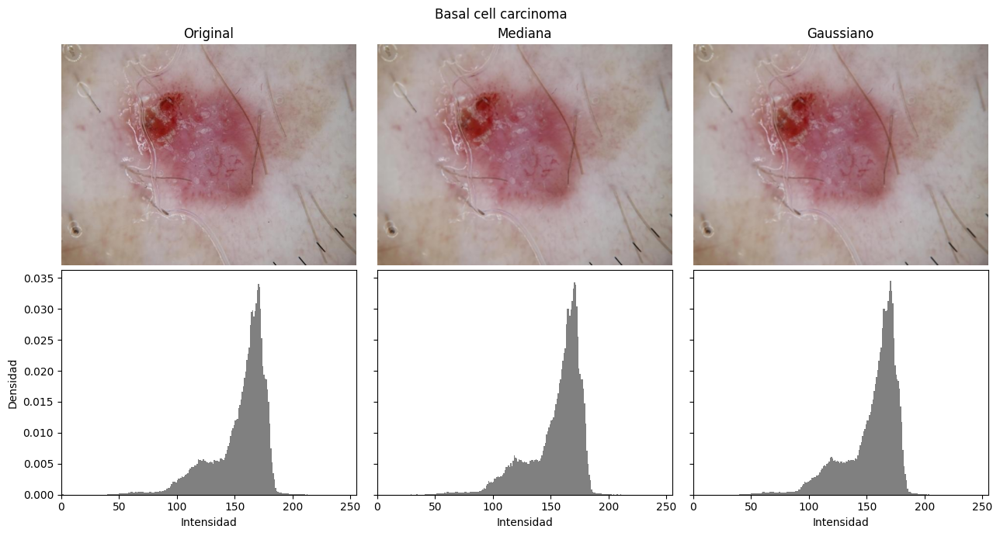

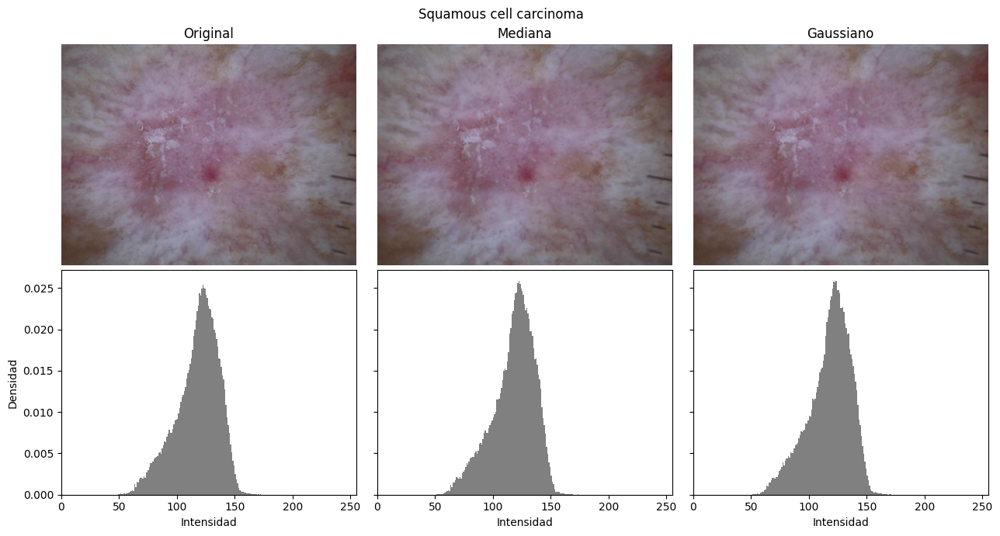

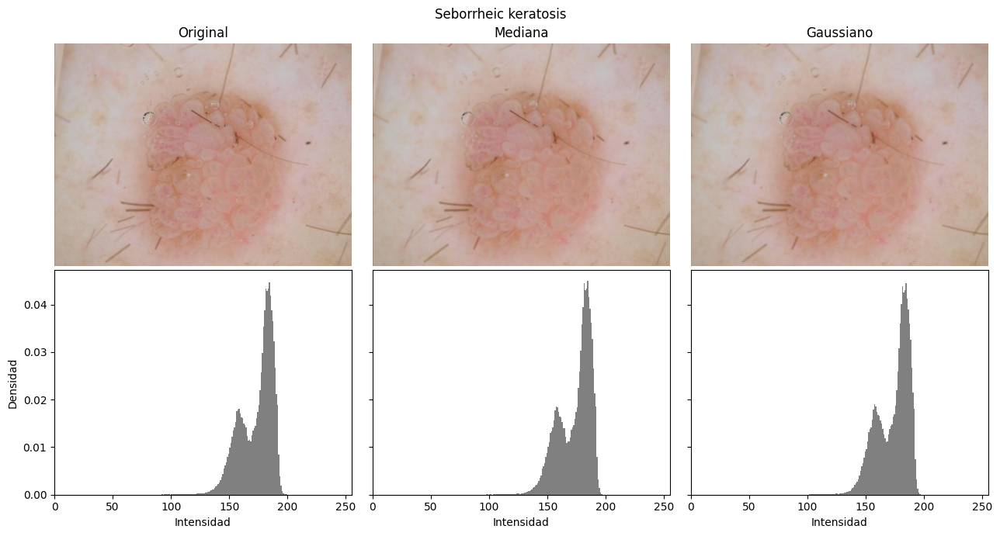

In [31]:
# Se recorre cada una de las tres imágenes seleccionadas.
# tipo = "BCC", "SCC" o "SK"; original = la imagen RGB correspondiente
for tipo, original in imagenes.items():

    # Diccionario con las tres versiones a comparar
    variantes = {
        "Original": original,
        "Mediana": cv2.medianBlur(original, 3),
        "Gaussiano": cv2.GaussianBlur(original, (3, 3), 1),
    }

    # Figura de 2 filas x 3 columnas
    fig, axes = plt.subplots(
        2, 3, figsize=(13, 7),
        sharex="row", sharey="row"
    )
    fig.suptitle(grupos[tipo])
    
    for columna, (nombre, imagen) in enumerate(variantes.items()):
        # Mostrar imagen
        axes[0, columna].imshow(imagen)
        axes[0, columna].set_title(nombre)
        axes[0, columna].axis("off")

        # Mostrar histograma en escala de grises
        gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)

        axes[1, columna].hist(
            gris.ravel(),
            bins=256,
            range=(0, 256),
            density=True,
            color="gray"
        )
        axes[1, columna].set_xlabel("Intensidad")
        axes[1, columna].set_xlim(0, 255)

    axes[1, 0].set_ylabel("Densidad")

    plt.tight_layout()
    plt.show()

### Resultado de la comparación

En el ejemplo de carcinoma basocelular, los filtros de mediana y
gaussiano con ventanas de 3 × 3 producen cambios visuales sutiles.
Los histogramas mantienen una distribución similar a la original.

La similitud entre histogramas no implica que se conserven todos los
detalles espaciales. Por ello, se requiere inspeccionar regiones ampliadas
y evaluar posteriormente el efecto sobre la segmentación.

Los pelos permanecen visibles tras el filtrado.

### Inspección ampliada y comparación cuantitativa del suavizado

Para evaluar el efecto de los filtros sobre los detalles finos, se
amplía un recorte central de 150 × 150 píxeles de cada imagen. Se
agregan además ventanas de 5 × 5 para observar cómo varía el efecto
al aumentar el tamaño del filtro.

Para la comparación cuantitativa se calculan, sobre la imagen en escala
de grises, indicadores asociados a la calidad de una imagen:

- **Brillo:** media de intensidad.
- **Contraste:** desvío estándar de la intensidad.
- **Nitidez:** magnitud media del gradiente calculado con el operador
  de Sobel, que es alta en bordes y detalles finos.
- **PSNR** (relación señal a ruido pico) respecto de la original: indica
  cuánto se modificó la imagen. Valores más altos implican mayor
  similitud con la original. Al no disponer de una imagen libre de ruido como referencia, el PSNR no
  mide la calidad absoluta, sino el grado de modificación introducido
  por cada filtro.

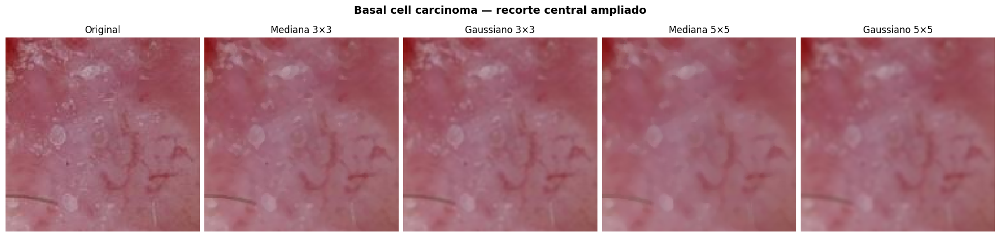

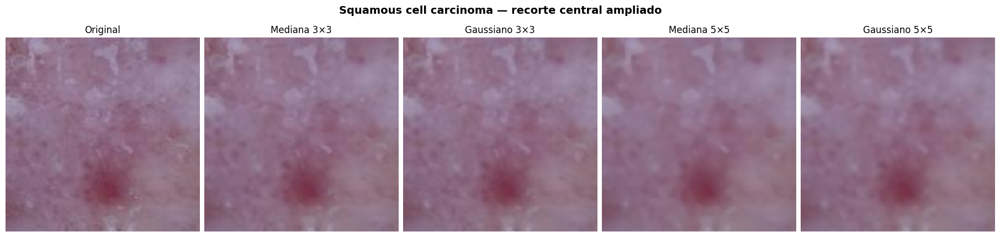

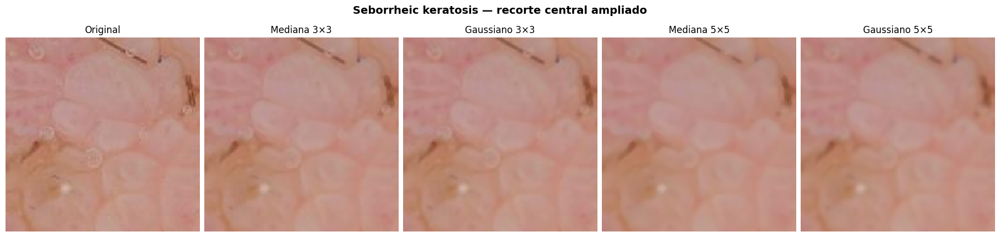

In [32]:
# Tamaño del recorte cuadrado, en píxeles
lado = 150

for tipo, original in imagenes.items():

    # Dimensiones de la imagen (alto = filas, ancho = columnas)
    alto, ancho = original.shape[:2]

    # Esquina superior izquierda del recorte, calculada para que quede
    # centrado en la imagen, donde suele estar la lesión.
    y0 = alto // 2 - lado // 2
    x0 = ancho // 2 - lado // 2

    # Se agregan ventanas de 5x5 para observar cómo cambia el efecto al aumentar el tamaño del filtro. 
    variantes = {
        "Original": original,
        "Mediana 3×3": cv2.medianBlur(original, 3),
        "Gaussiano 3×3": cv2.GaussianBlur(original, (3, 3), 1),
        "Mediana 5×5": cv2.medianBlur(original, 5),
        "Gaussiano 5×5": cv2.GaussianBlur(original, (5, 5), 1.5),
    }

    # Una fila de 5 paneles
    fig, axes = plt.subplots(
        1, 5, figsize=(18, 4.5), constrained_layout=True
    )
    fig.suptitle(
        f"{grupos[tipo]} — recorte central ampliado",
        fontsize=14, fontweight="bold"
    )

    for ax, (nombre, imagen) in zip(axes, variantes.items()):

        # Se muestra solo el recorte
        ax.imshow(
            imagen[y0:y0 + lado, x0:x0 + lado],
            interpolation="nearest"
        )
        ax.set_title(nombre)
        ax.axis("off")

    plt.show()

In [33]:
def metricas_calidad(gris, referencia):
    """
    Calcula indicadores de calidad sobre una imagen en escala de grises.
    gris: imagen a evaluar
    referencia: imagen original en grises, para calcular el PSNR
    Devuelve un diccionario con los valores.
    """

    # Gradiente con el operador de Sobel
    gx = cv2.Sobel(gris, cv2.CV_64F, 1, 0, ksize=3) # ksize=3 es el tamaño del kernel
    gy = cv2.Sobel(gris, cv2.CV_64F, 0, 1, ksize=3)

    # Magnitud del gradiente en cada píxel: es alta en bordes y detalles finos, y baja en zonas uniformes.
    # Su promedio se usa como medida de nitidez
    magnitud = np.sqrt(gx**2 + gy**2)

    # PSNR (relación señal a ruido pico) compara la imagen con la
    # original: cuanto MAYOR, MÁS PARECIDA. Si son idénticas, el
    # PSNR es infinito, por eso en ese caso se deja vacío (NaN)
    if np.array_equal(gris, referencia):
        psnr = np.nan
    else:
        psnr = cv2.PSNR(referencia, gris)

    return {
        "Brillo (media)": gris.mean(),
        "Contraste (desvío)": gris.std(),
        "Nitidez (gradiente medio)": magnitud.mean(),
        "PSNR vs original (dB)": psnr,
    }


# Lista donde se acumula una fila por cada combinación imagen-filtro
filas = []

for tipo, original in imagenes.items():

    # Mismas variantes que en la figura ampliada
    variantes = {
        "Original": original,
        "Mediana 3×3": cv2.medianBlur(original, 3),
        "Gaussiano 3×3": cv2.GaussianBlur(original, (3, 3), 1),
        "Mediana 5×5": cv2.medianBlur(original, 5),
        "Gaussiano 5×5": cv2.GaussianBlur(original, (5, 5), 1.5),
    }

    # La original en grises es la referencia para el PSNR
    gris_original = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    for nombre, imagen in variantes.items():
        gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)

        # agrega al diccionario todas las métricas devueltas por la función, junto con el grupo y el nombre del filtro
        filas.append({
            "Grupo": tipo,
            "Filtro": nombre,
            **metricas_calidad(gris, gris_original),
        })

metricas_suavizado = pd.DataFrame(filas)

# Mostrar la tabla redondeada a 2 decimales, sin la columna de índice
print(metricas_suavizado.round(2).to_string(index=False))

Grupo        Filtro  Brillo (media)  Contraste (desvío)  Nitidez (gradiente medio)  PSNR vs original (dB)
  BCC      Original          153.80               23.53                      19.48                    NaN
  BCC   Mediana 3×3          153.78               23.27                      15.62                  41.56
  BCC Gaussiano 3×3          153.79               23.21                      15.69                  41.72
  BCC   Mediana 5×5          153.79               22.96                      11.74                  36.55
  BCC Gaussiano 5×5          153.79               22.98                      12.72                  37.60
  SCC      Original          117.21               18.55                      17.61                    NaN
  SCC   Mediana 3×3          117.24               18.43                      14.44                  46.17
  SCC Gaussiano 3×3          117.21               18.41                      14.59                  46.86
  SCC   Mediana 5×5          117.28           

### Resultado de la comparación cuantitativa

En las tres imágenes, ningún filtro modifica de forma apreciable el
brillo (la media varía como máximo 0,1 niveles de gris) y el contraste
global disminuye menos de un 4 %. Esto es coherente con la similitud
de los histogramas observada previamente.

La nitidez, en cambio, se reduce entre un 16 % y un 20 % con las
ventanas de 3 × 3, y entre un 31 % y un 40 % con las de 5 × 5. Los
filtros atenúan los detalles finos aunque el histograma no cambie.

En los recortes ampliados se observa que las ventanas de 5 × 5 difuminan
estructuras propias de la lesión, como los vasos de la imagen BCC y los
contornos de los glóbulos de la imagen SK, mientras que los pelos más
gruesos permanecen visibles. Las diferencias entre mediana y gaussiano
del mismo tamaño son pequeñas.

Dado que el suavizado no elimina los artefactos principales y reduce
detalles que pueden ser relevantes para el análisis de textura, se
opta por no aumentar el tamaño de la ventana. La corrección de pelos
se aborda con un método específico en las secciones siguientes.

## Pruebas de mejora de contraste

Se comparan dos métodos de mejora de contraste: ecualización global del
histograma y ecualización adaptativa con limitación de contraste (CLAHE).

Ambos métodos se aplican sobre las versiones en escala de grises de las
tres imágenes seleccionadas, utilizando los mismos parámetros para todos
los diagnósticos. Se visualizan los resultados y sus histogramas para
evaluar los cambios en la distribución de intensidades y el realce de
detalles y artefactos.

El objetivo es identificar una alternativa que facilite la segmentación
posterior, procurando preservar las características relevantes de las
lesiones.

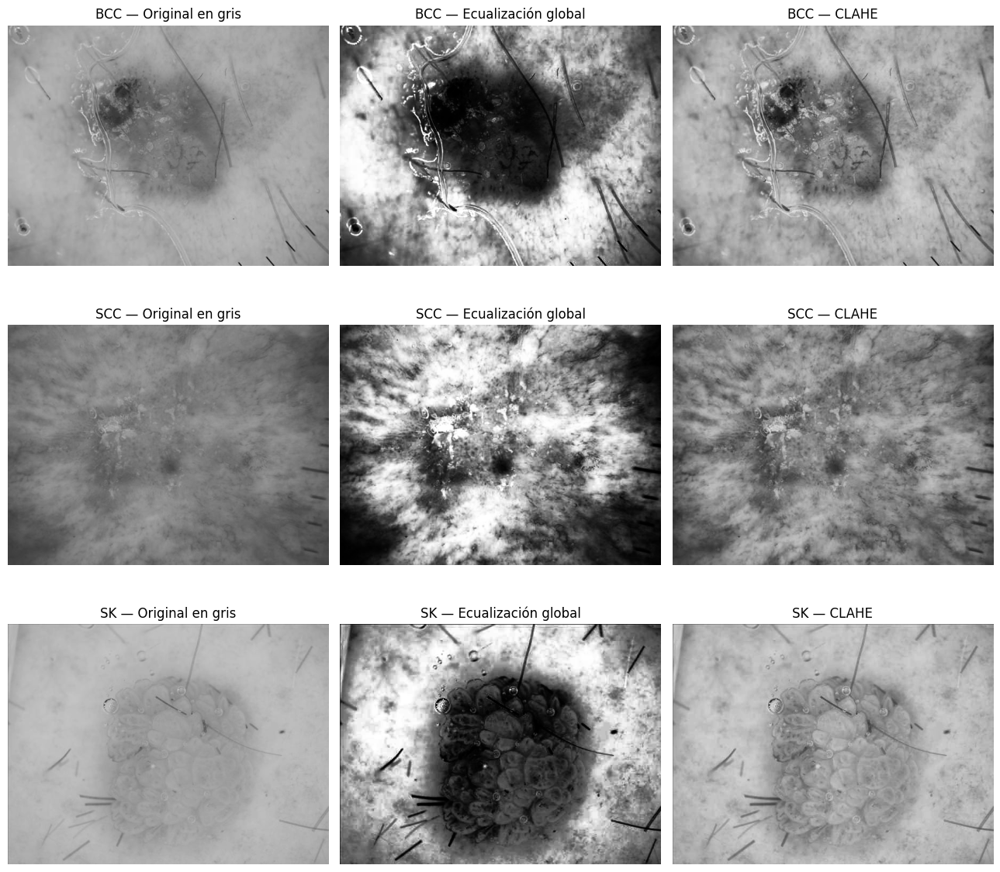

In [34]:
# Diccionario donde se guardan las variantes de cada imagen
contraste = {}

# Crear el objeto CLAHE (ecualización adaptativa con limitación de contraste). Divide la imagen en bloques y ecualiza cada uno por separado:
# - tileGridSize=(8, 8): la imagen se divide en una grilla de 8x8 bloques
# - clipLimit=2.0: límite de amplificación. El histograma de cada bloque se recorta a esa altura antes de ecualizar, para no amplificar demasiado el ruido en zonas uniformes
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Figura de 3 filas (una por imagen) x 3 columnas (una por variante)
fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    # Ambos métodos trabajan sobre un solo canal: se pasa a grises
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    variantes = {
        "Original en gris": gris,

        # Ecualización global
        "Ecualización global": cv2.equalizeHist(gris),

        # CLAHE: aplica el objeto creado arriba
        "CLAHE": clahe.apply(gris),
    }

    # Guardar las tres variantes de esta imagen
    contraste[tipo] = variantes

    for columna, (nombre, imagen) in enumerate(variantes.items()):
        # vmin/vmax fijos para que las tres se vean en la misma escala
        axes[fila, columna].imshow(
            imagen, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, columna].set_title(f"{tipo} — {nombre}")
        axes[fila, columna].axis("off")

plt.tight_layout()
plt.show()

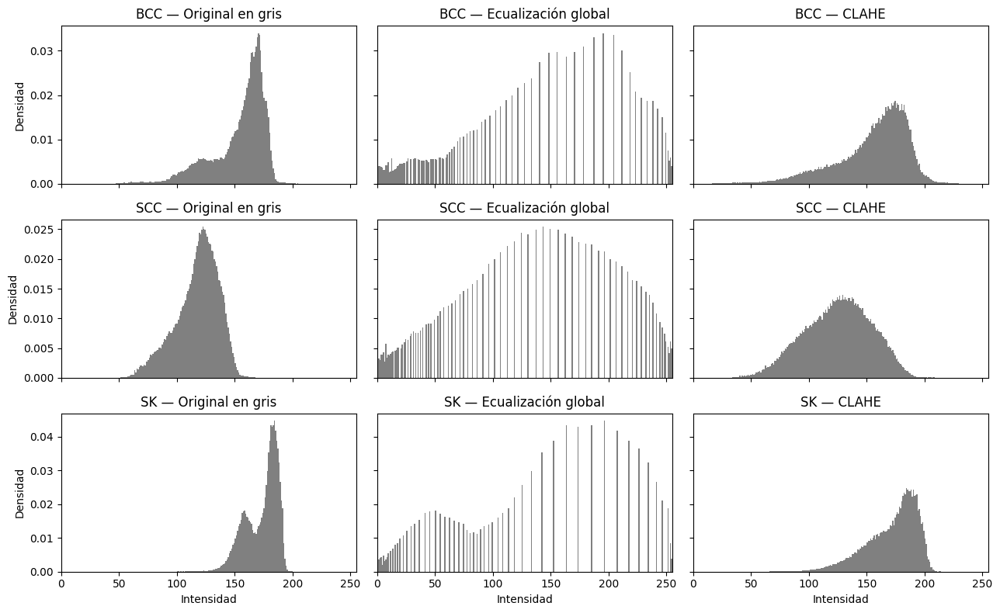

In [35]:
# Figura de 3x3 con los histogramas de las variantes de la celda anterior
fig, axes = plt.subplots(
    3, 3, figsize=(13, 8),
    sharex=True, sharey="row"
)

# "contraste" tiene, para cada imagen, sus tres variantes
for fila, (tipo, variantes) in enumerate(contraste.items()):
    for columna, (nombre, imagen) in enumerate(variantes.items()):
        ax = axes[fila, columna]

        # Histograma normalizado
        ax.hist(
            imagen.ravel(), bins=256,
            range=(0, 256), density=True, color="gray"
        )
        ax.set_title(f"{tipo} — {nombre}")
        ax.set_xlim(0, 255)

        if fila == 2:
            ax.set_xlabel("Intensidad")
        if columna == 0:
            ax.set_ylabel("Densidad")

plt.tight_layout()
plt.show()

### Comparación de los métodos de mejora de contraste

En los tres ejemplos, la ecualización global amplía el rango de
intensidades y produce un aumento pronunciado del contraste. Sin embargo,
también realza estructuras de la piel circundante y artefactos que podrían
interferir en la segmentación.

CLAHE produce un realce visual más moderado con los parámetros utilizados.
Por ello, se selecciona como alternativa preliminar para continuar el
desarrollo del pipeline, manteniendo los mismos parámetros para los tres
diagnósticos.

Esta selección deberá validarse mediante la segmentación y su evaluación
sobre más imágenes. La ampliación del histograma, por sí sola, no demuestra
una mejora en la delimitación de las lesiones.

### Comparación cuantitativa de la mejora de contraste

Se calculan sobre cada variante los mismos indicadores utilizados en
el suavizado (brillo, contraste, nitidez y PSNR respecto de la imagen
sin mejorar).

Dado que el objetivo del preprocesamiento es facilitar la segmentación,
se agrega un indicador de separación centro-borde: la diferencia
entre la intensidad media de un recuadro central (30 % del alto y del
ancho) y la de un marco exterior (5 % del borde), dividida por el desvío
estándar de toda la imagen. Se supone que el centro corresponde
mayormente a la lesión y el borde a piel sana, el mismo supuesto que
utiliza GrabCut. La normalización por el desvío evita que un simple
estiramiento del rango de grises se interprete como mejor separación.

Además de la escala de grises, se evalúa el canal G, que en la
caracterización mostró mayor contraste entre la lesión y la piel,
con y sin CLAHE.

In [36]:
def separacion_centro_borde(gris, fraccion_centro=0.3, fraccion_borde=0.05):
    """
    Estima qué tan diferenciada está la región central (donde se
    supone que está la lesión) del borde de la imagen (piel).
    gris: imagen de un canal
    fraccion_centro: tamaño del recuadro central, como fracción
                     del alto y del ancho (0.3 = 30 %)
    fraccion_borde: grosor del marco exterior (0.05 = 5 %)
    Devuelve |media del borde - media del centro| / desvío global.
    """

    alto, ancho = gris.shape

    # Región central
    y0 = int(alto * (1 - fraccion_centro) / 2)
    x0 = int(ancho * (1 - fraccion_centro) / 2)
    centro = gris[y0:alto - y0, x0:ancho - x0]

    #  Marco exterior
    my = max(1, int(alto * fraccion_borde))
    mx = max(1, int(ancho * fraccion_borde))

    # Máscara booleana: True en toda la imagen y luego False en el
    # interior, de modo que solo queda True en el marco exterior.
    marco = np.ones_like(gris, dtype=bool)
    marco[my:alto - my, mx:ancho - mx] = False
    borde = gris[marco]

    # Diferencia entre las medias, dividida por el desvío global.
    return abs(borde.mean() - centro.mean()) / gris.std()

In [37]:
# Mismo objeto CLAHE
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

# Lista donde se acumula una fila por cada combinación imagen-variante
filas = []

for tipo, original in imagenes.items():
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Canal G 
    verde = original[:, :, 1]

    # Cada variante es un par (imagen, referencia)
    variantes = {
        "Gris original": (gris, gris),
        "Gris + ecualización global": (cv2.equalizeHist(gris), gris),
        "Gris + CLAHE": (clahe.apply(gris), gris),
        "Canal G original": (verde, verde),
        "Canal G + CLAHE": (clahe.apply(verde), verde),
    }

    for nombre, (imagen, referencia) in variantes.items():
        fila = {"Grupo": tipo, "Variante": nombre}

        # Métricas de calidad: función definida en la sección de suavizado (brillo, contraste, nitidez y PSNR)
        fila.update(metricas_calidad(imagen, referencia))

        # Separación entre la región central y el borde
        fila["Separación centro-borde"] = separacion_centro_borde(imagen)

        filas.append(fila)

metricas_contraste = pd.DataFrame(filas)
print(metricas_contraste.round(2).to_string(index=False))

Grupo                   Variante  Brillo (media)  Contraste (desvío)  Nitidez (gradiente medio)  PSNR vs original (dB)  Separación centro-borde
  BCC              Gris original          153.80               23.53                      19.48                    NaN                     1.79
  BCC Gris + ecualización global          129.81               74.49                      66.10                  12.68                     1.45
  BCC               Gris + CLAHE          154.74               31.48                      43.02                  25.84                     1.27
  BCC           Canal G original          146.53               28.92                      20.33                    NaN                     2.02
  BCC            Canal G + CLAHE          150.33               34.21                      43.78                  24.88                     1.42
  SCC              Gris original          117.21               18.55                      17.61                    NaN                  

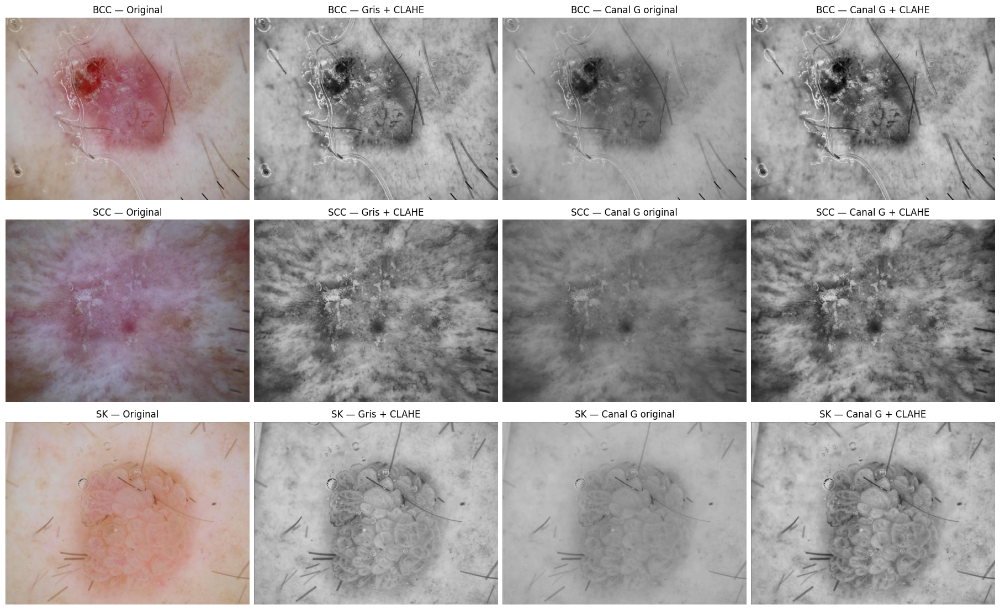

In [38]:
# Figura de 3 filas (una por imagen) x 4 columnas
fig, axes = plt.subplots(
    3, 4, figsize=(18, 11), constrained_layout=True
)

for fila, (tipo, original) in enumerate(imagenes.items()):
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    verde = original[:, :, 1]

    # Variantes a comparar visualmente (todas de un solo canal)
    paneles = {
        "Gris + CLAHE": clahe.apply(gris),
        "Canal G original": verde,
        "Canal G + CLAHE": clahe.apply(verde),
    }

    # Primera columna: imagen original en color, como referencia
    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    # Columnas 2 a 4: variantes en escala de grises.
    for columna, (nombre, imagen) in enumerate(paneles.items(), 1):
        axes[fila, columna].imshow(
            imagen, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, columna].set_title(f"{tipo} — {nombre}")

    for ax in axes[fila]:
        ax.axis("off")

plt.show()

### Resultado de la comparación cuantitativa del contraste

La ecualización global triplica el desvío estándar (de 14–24 a ~74) y
desplaza el brillo medio hacia el centro del rango (~130). También
multiplica la nitidez por 3 a 5, y su PSNR (11–13 dB) indica una
modificación muy fuerte de la imagen. CLAHE produce un efecto más
moderado: aumenta el contraste entre un 34 % y un 56 %, duplica
aproximadamente la nitidez y modifica menos la imagen (PSNR de
24–28 dB). Esto confirma cuantitativamente la observación visual previa.

Sin embargo, en las tres imágenes ambos métodos reducen la
separación centro-borde, y CLAHE es el que más la reduce (por ejemplo,
en BCC pasa de 1,79 a 1,27). Ambos métodos amplifican por igual la
textura de la piel, los pelos y los detalles de la lesión, aumentando la
variabilidad general más que la diferencia entre lesión y piel. CLAHE,
al ecualizar cada bloque por separado, atenúa además las diferencias de
intensidad de gran escala, como la que existe entre la lesión y su entorno.

El canal G sin mejorar presenta la mayor separación en BCC (2,02) y SK
(1,85). En SCC, donde la lesión ocupa la mayor parte de la imagen, el
supuesto de lesión central y piel en el borde no se cumple, por lo que
el indicador no resulta confiable para esa imagen.

Estos resultados sugieren que la mejora de contraste, si bien facilita
la inspección visual, podría no favorecer una segmentación basada en
umbrales. Por ello, en la etapa de segmentación se compara el uso de
CLAHE con el del canal G sin mejorar. Asimismo, dado que ambos métodos
modifican la textura, las características de textura se calcularán
sobre la imagen sin ecualizar.

## Detección de posibles pelos y artefactos oscuros
Los pelos y otros artefactos oscuros generan
bordes que no pertenecen a la lesión y pueden interferir en la
segmentación. Para atenuarlos se aplica un procedimiento en cuatro pasos:

1. **Transformación black-hat** sobre la imagen en escala de grises,
   calculada como la diferencia entre el cierre de la imagen y la imagen
   original. Resalta las estructuras oscuras más finas que el elemento
   estructurante utilizado.
2. **Umbralización** de la respuesta del black-hat, para obtener una
   máscara de posibles artefactos.
3. **Refinamiento morfológico** de la máscara.
4. **Inpainting**, que reemplaza los píxeles marcados por valores
   estimados a partir de su entorno.

El resultado depende de dos parámetros: el tamaño del elemento
estructurante y el umbral. Un elemento demasiado chico no abarca el
ancho de los pelos, y uno demasiado grande incluye estructuras de la
lesión. Un umbral alto omite artefactos, y uno bajo marca también
detalles de la lesión. Por ello, se realiza un barrido de ambos
parámetros y se utilizan los mismos valores para las tres imágenes.

In [39]:
# Tamaños del elemento estructurante (en píxeles) y umbrales a evaluar
tamanios_kernel = [9, 17, 25]
umbrales = [20, 30, 40, 50]

# Lista donde se acumula una fila por cada combinación imagen-kernel
filas = []

for tipo, original in imagenes.items():

    # El black-hat se calcula sobre la imagen en escala de grises
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    for tamanio in tamanios_kernel:

        # Elemento estructurante circular (elipse de lados iguales).
        # El black-hat resalta estructuras oscuras MÁS FINAS que él
        kernel_prueba = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (tamanio, tamanio)
        )

        # Black-hat = cierre(imagen) - imagen.
        # "tapa" las estructuras oscuras más finas que el kernel, rellenándolas
        # con el valor de su entorno. Al restar la original, solo
        # quedan con valores altos esas estructuras: pelos, marcas, bordes oscuros finos
        blackhat = cv2.morphologyEx(
            gris, cv2.MORPH_BLACKHAT, kernel_prueba
        )

        registro = {"Grupo": tipo, "Kernel": f"{tamanio}×{tamanio}"}

        for u in umbrales:
            # True donde la respuesta supera el umbral
            registro[f"Umbral {u}"] = 100 * (blackhat > u).mean()

        filas.append(registro)

barrido_parametros = pd.DataFrame(filas)

print("Porcentaje de píxeles marcados como posible artefacto:\n")
print(barrido_parametros.round(2).to_string(index=False))

Porcentaje de píxeles marcados como posible artefacto:

Grupo Kernel  Umbral 20  Umbral 30  Umbral 40  Umbral 50
  BCC    9×9       2.68       1.04       0.47       0.26
  BCC  17×17       5.59       2.48       1.16       0.59
  BCC  25×25       9.12       4.41       2.29       1.31
  SCC    9×9       0.47       0.15       0.02       0.00
  SCC  17×17       1.48       0.32       0.11       0.01
  SCC  25×25       3.64       0.69       0.18       0.03
   SK    9×9       1.71       0.96       0.61       0.15
   SK  17×17       2.20       1.18       0.71       0.21
   SK  25×25       2.59       1.32       0.79       0.26


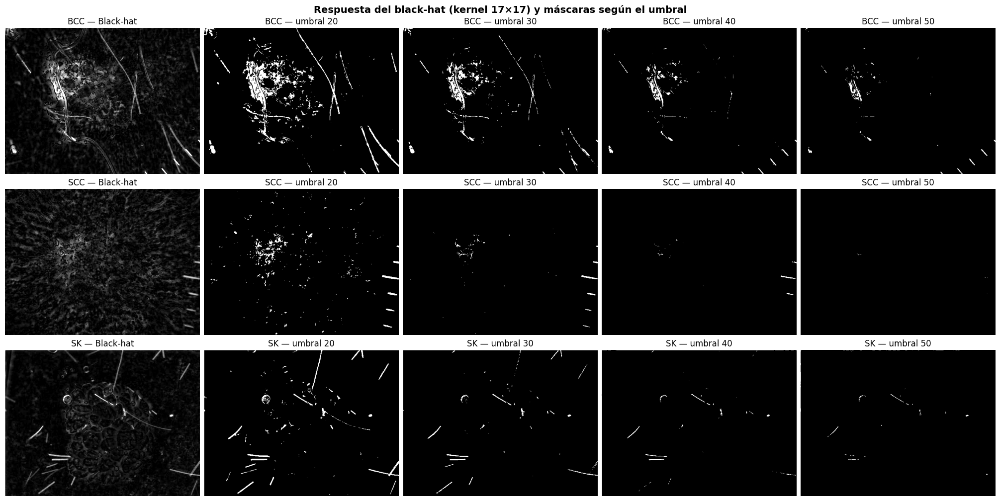

In [40]:
# Kernel de 17x17 para visualizar el efecto del umbral
kernel_blackhat = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))

# Se guarda la respuesta del black-hat de cada imagen
respuestas_blackhat = {}

# Figura:
fig, axes = plt.subplots(
    3, len(umbrales) + 1, figsize=(20, 10), constrained_layout=True
)
fig.suptitle(
    "Respuesta del black-hat (kernel 17×17) y máscaras según el umbral",
    fontsize=14, fontweight="bold"
)

for fila, (tipo, original) in enumerate(imagenes.items()):
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    blackhat = cv2.morphologyEx(gris, cv2.MORPH_BLACKHAT, kernel_blackhat)
    respuestas_blackhat[tipo] = blackhat

    # Respuesta del black-hat. vmax=60 estira la escala de grises
    # para que se vean las respuestas débiles (casi todas son < 60)
    axes[fila, 0].imshow(blackhat, cmap="gray", vmin=0, vmax=60)
    axes[fila, 0].set_title(f"{tipo} — Black-hat")

    # Máscara para cada umbral (blanco = posible artefacto).
    for columna, u in enumerate(umbrales, 1):
        axes[fila, columna].imshow(blackhat > u, cmap="gray")
        axes[fila, columna].set_title(f"{tipo} — umbral {u}")

    for ax in axes[fila]:
        ax.axis("off")

plt.show()

### Elección de parámetros

**Tamaño del elemento estructurante:** Con un kernel de 9 × 9 se detecta
menos de la mitad de los píxeles que con 17 × 17 en BCC y SCC, y se
pierden pelos. Al pasar de 17 × 17 a 25 × 25, en SK, donde los
artefactos son principalmente pelos, el porcentaje marcado casi no
cambia (de 2,20 % a 2,59 % con umbral 20), lo que indica que los pelos
ya quedan contenidos con 17 × 17. En BCC, en cambio, aumenta de 5,59 %
a 9,12 %, porque el kernel mayor empieza a incluir estructuras de la
lesión. Se selecciona un kernel de 17 × 17.

**Umbral:** Con un umbral de 50 la mayoría de los pelos no se detecta. Con 20 se
detectan casi todos los pelos, pero también estructuras de la lesión,
en especial en BCC. Con un umbral de 30, la máscara incluye
la mayoría de los pelos oscuros, con menor
inclusión de la lesión, por lo que se adopta como compromiso.

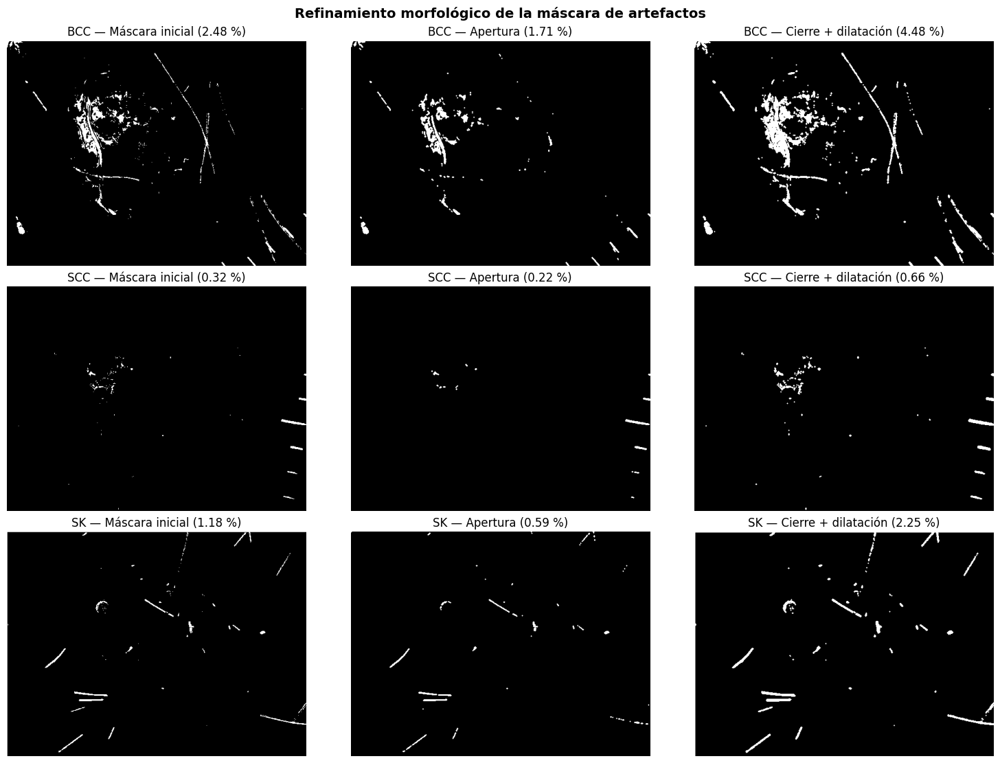

In [41]:
# Parámetros elegidos a partir del barrido
umbral_artefactos = 30

# Elemento estructurante chico (3x3) para refinar la máscara
kernel_refinamiento = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

fig, axes = plt.subplots(3, 3, figsize=(15, 11), constrained_layout=True)
fig.suptitle(
    "Refinamiento morfológico de la máscara de artefactos",
    fontsize=14, fontweight="bold"
)

for fila, tipo in enumerate(imagenes):

    # Máscara inicial: umbralización binaria del black-hat.
    _, mascara = cv2.threshold(
        respuestas_blackhat[tipo], umbral_artefactos, 255,
        cv2.THRESH_BINARY
    )

    # Opción A — Apertura 
    apertura = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, kernel_refinamiento)

    # Opción B — Cierre 
    cierre = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel_refinamiento)
    cierre_dilatacion = cv2.dilate(cierre, kernel_refinamiento, iterations=1)

    paneles = {
        "Máscara inicial": mascara,
        "Apertura": apertura,
        "Cierre + dilatación": cierre_dilatacion,
    }

    for columna, (nombre, resultado) in enumerate(paneles.items()):
        axes[fila, columna].imshow(resultado, cmap="gray", vmin=0, vmax=255)

        # Se agrega al título el % de píxeles marcados en cada variante
        porcentaje = 100 * (resultado > 0).mean()
        axes[fila, columna].set_title(
            f"{tipo} — {nombre} ({porcentaje:.2f} %)"
        )
        axes[fila, columna].axis("off")

plt.show()

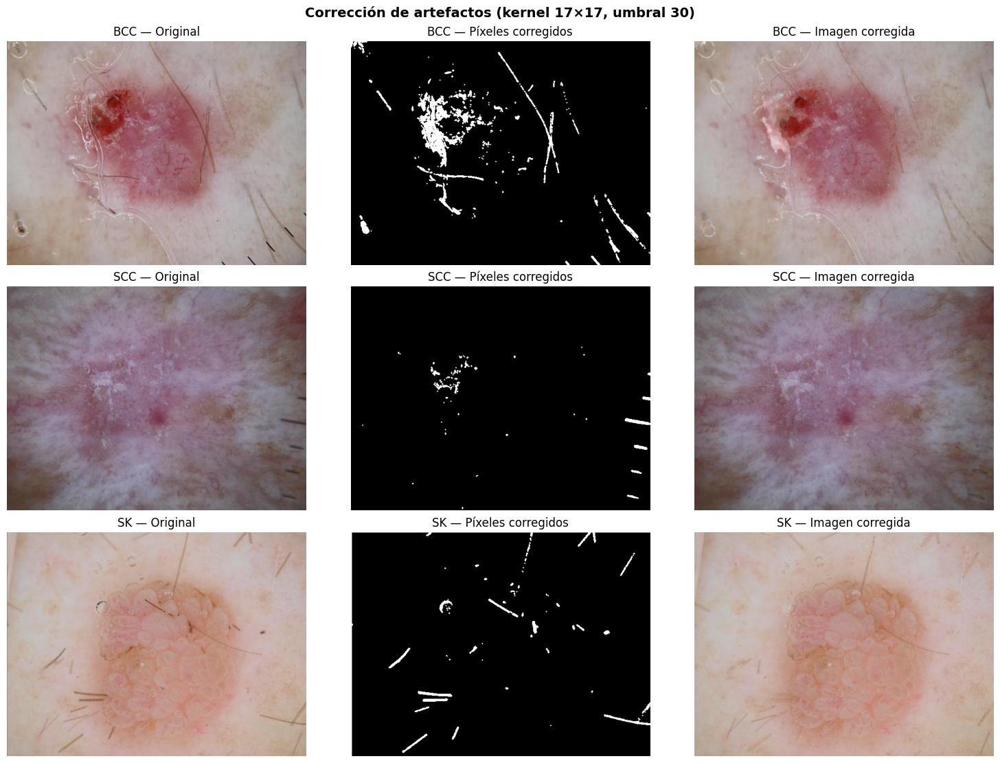

In [42]:
def corregir_artefactos(imagen_rgb, tamanio_kernel=17, umbral=30):
    """
    Detecta pelos y artefactos oscuros y los corrige por inpainting.
    imagen_rgb: imagen original en RGB
    tamanio_kernel: tamaño del elemento estructurante del black-hat
    umbral: respuesta mínima del black-hat para marcar un píxel
    Devuelve (imagen corregida, máscara de píxeles corregidos).
    """

    # 1) Black-hat sobre la imagen en escala de grises
    gris = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (tamanio_kernel, tamanio_kernel)
    )
    blackhat = cv2.morphologyEx(gris, cv2.MORPH_BLACKHAT, kernel)

    # 2) Umbralización: blanco = posible artefacto
    _, mascara = cv2.threshold(blackhat, umbral, 255, cv2.THRESH_BINARY)

    # 3) Refinamiento: cierre para unir cortes y dilatación para
    #    cubrir el borde de cada pelo (kernel chico de 3x3)
    kernel_chico = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel_chico)
    mascara = cv2.dilate(mascara, kernel_chico, iterations=1)

    # 4) Inpainting: rellena los píxeles marcados estimando su valor a
    #    partir de los vecinos no marcados. 3 = radio del vecindario.
    #    INPAINT_TELEA avanza desde el borde de la región hacia adentro
    corregida = cv2.inpaint(imagen_rgb, mascara, 3, cv2.INPAINT_TELEA)

    return corregida, mascara


# Diccionarios con los resultados de cada imagen.
imagenes_corregidas = {}
mascaras_artefactos = {}

fig, axes = plt.subplots(3, 3, figsize=(15, 11), constrained_layout=True)
fig.suptitle(
    f"Corrección de artefactos (kernel 17×17, umbral {umbral_artefactos})",
    fontsize=14, fontweight="bold"
)

for fila, (tipo, original) in enumerate(imagenes.items()):
    corregida, mascara = corregir_artefactos(
        original, tamanio_kernel=17, umbral=umbral_artefactos
    )
    imagenes_corregidas[tipo] = corregida
    mascaras_artefactos[tipo] = mascara

    paneles = [
        ("Original", original, None),
        ("Píxeles corregidos", mascara, "gray"),
        ("Imagen corregida", corregida, None),
    ]

    for columna, (nombre, imagen, cmap) in enumerate(paneles):
        axes[fila, columna].imshow(imagen, cmap=cmap)
        axes[fila, columna].set_title(f"{tipo} — {nombre}")
        axes[fila, columna].axis("off")

plt.show()

In [43]:
def artefactos_residuales(imagen_rgb, kernel, limite=20):
    """
    Estima cuántas estructuras oscuras y finas quedan en una imagen:
    porcentaje de píxeles cuya respuesta del black-hat supera "limite".
    Un valor menor indica menos pelos y artefactos remanentes.
    """
    gris = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2GRAY)
    blackhat = cv2.morphologyEx(gris, cv2.MORPH_BLACKHAT, kernel)
    return 100 * (blackhat > limite).mean()


filas = []

for tipo, original in imagenes.items():

    # Estructuras finas oscuras antes y después de la corrección
    antes = artefactos_residuales(original, kernel_blackhat)
    despues = artefactos_residuales(imagenes_corregidas[tipo], kernel_blackhat)

    filas.append({
        "Grupo": tipo,
        # Porcentaje de la imagen modificado por el inpainting
        "% de píxeles corregidos": 100 * (mascaras_artefactos[tipo] > 0).mean(),
        "Residual antes (%)": antes,
        "Residual después (%)": despues,
        # Reducción relativa: cuánto bajó respecto del valor inicial
        "Reducción (%)": 100 * (antes - despues) / antes,
    })

evaluacion_artefactos = pd.DataFrame(filas)
print(evaluacion_artefactos.round(2).to_string(index=False))

Grupo  % de píxeles corregidos  Residual antes (%)  Residual después (%)  Reducción (%)
  BCC                     4.48                5.59                  2.26          59.60
  SCC                     0.66                1.48                  0.94          36.79
   SK                     2.25                2.20                  0.54          75.24


### Resultado de la corrección de artefactos

En el refinamiento, la apertura reduce la máscara a cerca de la mitad
en SK (de 1,18 % a 0,59 %) porque elimina los pelos más finos, por lo
que se descarta. El cierre seguido de dilatación une los tramos
discontinuos de cada pelo y amplía levemente su cobertura, por lo que
se adopta para la corrección.

Con los parámetros seleccionados se corrige el 4,5 % de la imagen en
BCC, el 0,7 % en SCC y el 2,3 % en SK. Para cuantificar el efecto, se
calcula la proporción de píxeles con respuesta del black-hat mayor que
20 antes y después de la corrección. Esta proporción disminuye un 60 %
en BCC, un 37 % en SCC y un 75 % en SK. 

Visualmente, se eliminan la mayoría de los pelos oscuros en BCC, SK y SCC.
Sin embargo, persisten los pelos finos y
de bajo contraste, que el black-hat no distingue de la piel. Además, en
BCC la máscara incluye parte de la región oscura de la lesión, que
resulta modificada por el inpainting.

Por este motivo, la imagen corregida se utiliza como entrada para la
segmentación, donde los pelos generan bordes falsos, mientras que las
características de color y textura se calcularán sobre la imagen
original para no incluir valores estimados por el inpainting.

## Primera prueba de segmentación: efecto de la corrección de artefactos

Se comparan dos alternativas: imagen original e imagen corregida mediante
inpainting. Ambas se convierten a escala de grises y se procesan con
CLAHE utilizando los mismos parámetros.

Luego se aplica Otsu, que determina automáticamente un umbral para cada
imagen. Se utiliza umbralización inversa para representar en blanco las
regiones oscuras consideradas candidatas a lesión.

Esta es una prueba inicial: las regiones oscuras también pueden incluir
pelos, marcas o piel circundante. Se comparan las máscaras y sus contornos
sobre la imagen original para evaluar visualmente sus limitaciones.

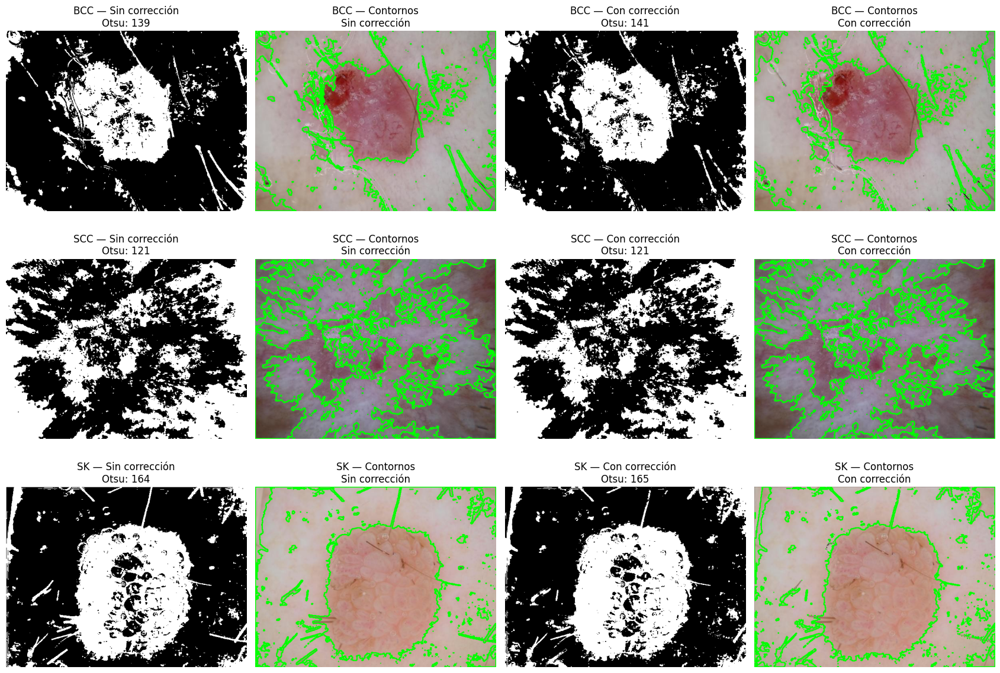

In [44]:
mascaras_otsu = {}

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

fig, axes = plt.subplots(3, 4, figsize=(17, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):

    variantes = {
        "Sin corrección": original,
        "Con corrección": imagenes_corregidas[tipo],
    }

    mascaras_otsu[tipo] = {}

    for columna, (nombre, imagen) in enumerate(variantes.items()):
        gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)
        mejorada = clahe.apply(gris)

        umbral, mascara = cv2.threshold(
            mejorada, 0, 255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        mascaras_otsu[tipo][nombre] = mascara

        # Mostrar máscara
        axes[fila, 2 * columna].imshow(
            mascara, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, 2 * columna].set_title(
            f"{tipo} — {nombre}\nOtsu: {umbral:.0f}"
        )

        # Mostrar contornos sobre la original
        contornos, _ = cv2.findContours(
            mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )

        superpuesta = original.copy()
        cv2.drawContours(
            superpuesta, contornos, -1, (0, 255, 0), 2
        )

        axes[fila, 2 * columna + 1].imshow(superpuesta)
        axes[fila, 2 * columna + 1].set_title(
            f"{tipo} — Contornos\n{nombre}"
        )

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## Segmentación mediante GrabCut

La segmentación mediante Otsu presentó regiones fragmentadas y dificultades
para separar la lesión de la piel circundante. Por ello, se evaluó GrabCut
como método alternativo, que utiliza información de color y relaciones
entre píxeles vecinos para separar primer plano y fondo.

Se definió un rectángulo inicial excluyendo un margen del 5 % de la imagen,
considerado fondo, y se aplicaron cinco iteraciones. Se utilizaron los
mismos parámetros para los tres diagnósticos.

Las máscaras obtenidas presentaron regiones más continuas que las de Otsu,
aunque persistió la inclusión de piel circundante y algunos artefactos.
Como refinamiento, se conservó el componente conectado de mayor área,
suponiendo que corresponde a la lesión principal, para eliminar pequeñas
regiones aisladas.

Finalmente, se visualizaron los contornos sobre las imágenes originales
para inspeccionar la delimitación. Esta comparación es cualitativa y no
demuestra por sí sola una mayor precisión de segmentación.

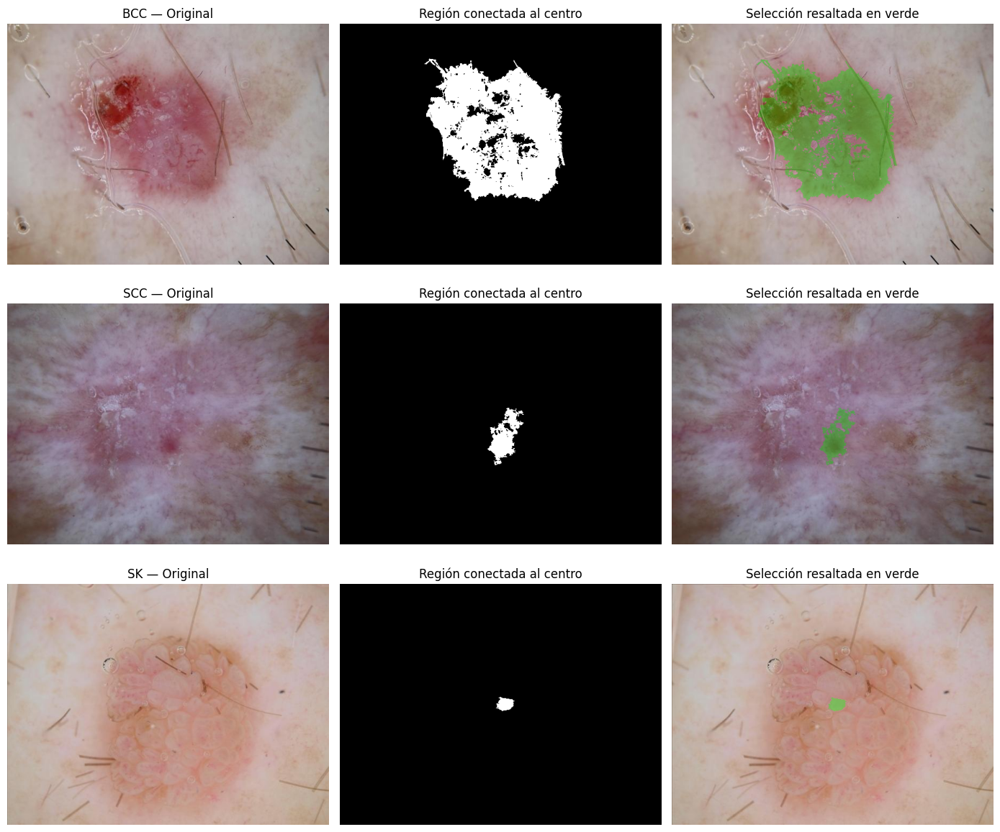

In [45]:
mascaras_lesion = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    mascara = mascaras_otsu[tipo]["Con corrección"]
    alto, ancho = mascara.shape

    # Considerar candidata la clase presente en el centro:
    # puede ser blanca o negra en la máscara de Otsu
    valor_central = mascara[alto // 2, ancho // 2]
    candidata = (mascara == valor_central).astype("uint8")

    # Conservar solamente la región conectada al centro
    _, etiquetas = cv2.connectedComponents(candidata, connectivity=8)
    etiqueta_central = etiquetas[alto // 2, ancho // 2]

    seleccion = (
        (etiquetas == etiqueta_central).astype("uint8") * 255
    )

    mascaras_lesion[tipo] = seleccion

    # Resaltar los píxeles seleccionados sobre la original
    superpuesta = original.copy()
    dentro = seleccion > 0
    superpuesta[dentro] = (
        0.65 * original[dentro] + 0.35 * np.array([0, 255, 0])
    ).astype("uint8")

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(
        seleccion, cmap="gray", vmin=0, vmax=255
    )
    axes[fila, 1].set_title("Región conectada al centro")

    axes[fila, 2].imshow(superpuesta)
    axes[fila, 2].set_title("Selección resaltada en verde")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

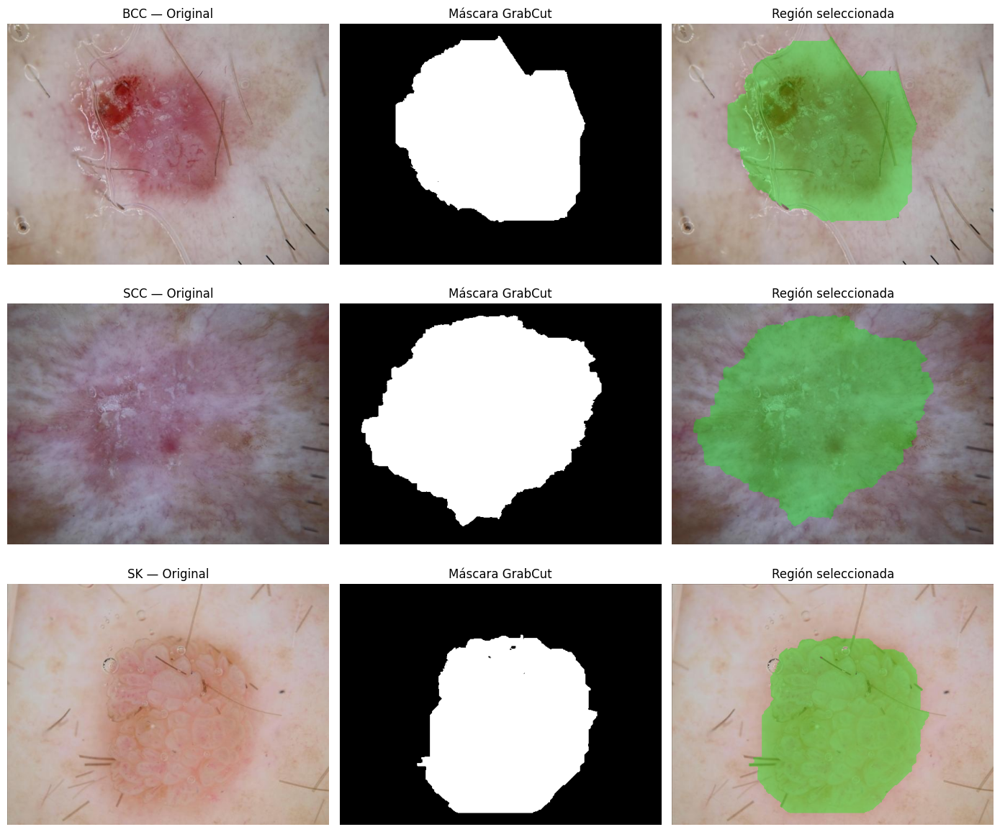

In [46]:
mascaras_grabcut = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    alto, ancho = original.shape[:2]

    # Rectángulo inicial: excluye un margen del 5 %
    mx = max(1, int(ancho * 0.05))
    my = max(1, int(alto * 0.05))
    rectangulo = (mx, my, ancho - 2 * mx, alto - 2 * my)

    etiquetas = np.zeros((alto, ancho), dtype=np.uint8)
    modelo_fondo = np.zeros((1, 65), dtype=np.float64)
    modelo_lesion = np.zeros((1, 65), dtype=np.float64)

    cv2.setRNGSeed(42)
    cv2.grabCut(
        original, etiquetas, rectangulo,
        modelo_fondo, modelo_lesion,
        5, cv2.GC_INIT_WITH_RECT
    )

    # Primer plano seguro o probable
    mascara = np.where(
        (etiquetas == cv2.GC_FGD) |
        (etiquetas == cv2.GC_PR_FGD),
        255, 0
    ).astype("uint8")

    mascaras_grabcut[tipo] = mascara

    superpuesta = original.copy()
    dentro = mascara > 0
    superpuesta[dentro] = (
        0.65 * original[dentro] +
        0.35 * np.array([0, 255, 0])
    ).astype("uint8")

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(
        mascara, cmap="gray", vmin=0, vmax=255
    )
    axes[fila, 1].set_title("Máscara GrabCut")

    axes[fila, 2].imshow(superpuesta)
    axes[fila, 2].set_title("Región seleccionada")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

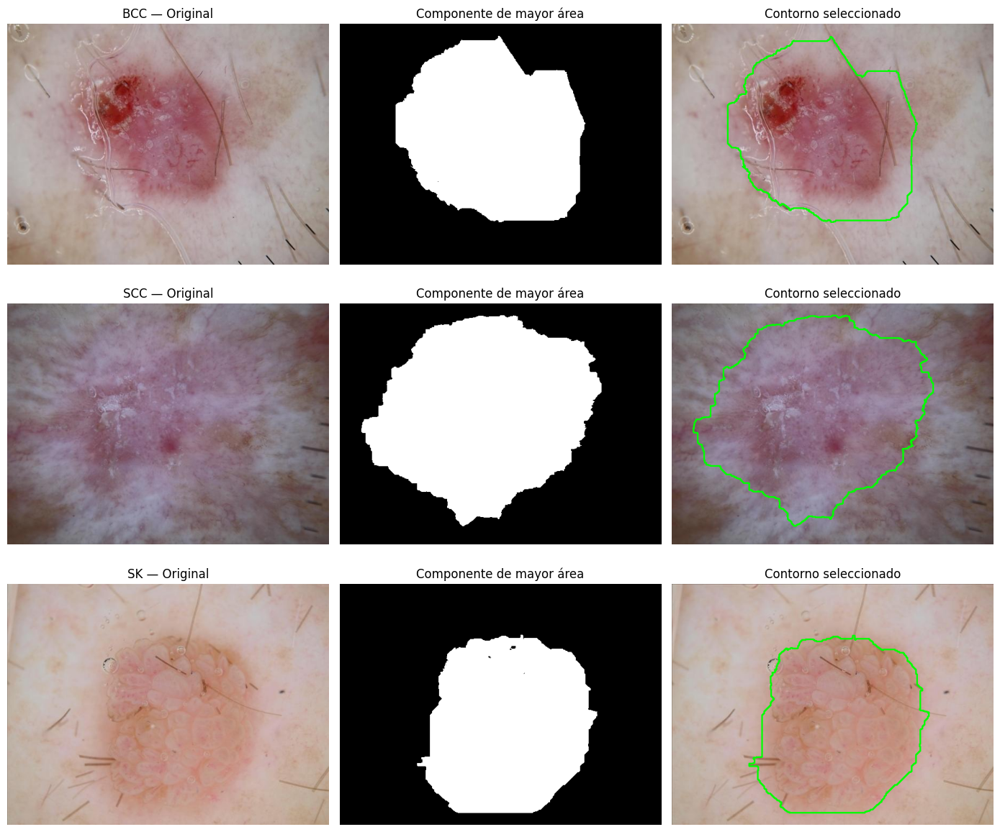

In [47]:
mascaras_limpias = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    mascara = mascaras_grabcut[tipo]

    # Identificar las regiones blancas conectadas
    cantidad, etiquetas, estadisticas, _ = (
        cv2.connectedComponentsWithStats(mascara, connectivity=8)
    )

    limpia = np.zeros_like(mascara)

    if cantidad > 1:
        # La etiqueta 0 es el fondo
        mayor = 1 + np.argmax(
            estadisticas[1:, cv2.CC_STAT_AREA]
        )
        limpia[etiquetas == mayor] = 255

    mascaras_limpias[tipo] = limpia

    # Dibujar solamente el contorno de la región seleccionada
    contornos, _ = cv2.findContours(
        limpia, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    resultado = original.copy()
    cv2.drawContours(resultado, contornos, -1, (0, 255, 0), 2)

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(
        limpia, cmap="gray", vmin=0, vmax=255
    )
    axes[fila, 1].set_title("Componente de mayor área")

    axes[fila, 2].imshow(resultado)
    axes[fila, 2].set_title("Contorno seleccionado")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [48]:
%matplotlib inline